# Lab 1: Feature engineering and feature selection

Check the tools, understand the data, build features, and choose among them without leakage.

This notebook follows the Lab 1 handout: Parts A to D, then the *Try it yourself* extensions
and the *Check your understanding* questions. The code saves every chart and table to
`results/lab01/` as it runs.

In [1]:
import json
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LogisticRegression, Ridge
from sklearn.metrics import mean_absolute_error, pairwise_distances, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Notebooks live in all_experiments/, so the course folder is one level up.
PROJECT_ROOT = Path.cwd().parent
DATA = PROJECT_ROOT / "all_datasets"
RESULTS = PROJECT_ROOT / "results" / "lab01"
RESULTS.mkdir(parents=True, exist_ok=True)
summary = {}  # headline numbers, saved to results/lab01/summary.json at the end

# Dark charts to match the README. Cyan and orange pass a colour-blindness check on this background.
CYAN, ORANGE, INK, MUTED, GRID = "#2f9fd6", "#d86f2e", "#e6edf3", "#8b949e", "#30363d"
plt.rcParams.update({
    "figure.facecolor": "#0d1117", "axes.facecolor": "#0d1117", "savefig.facecolor": "#0d1117",
    "text.color": INK, "axes.labelcolor": "#c9d1d9", "axes.edgecolor": GRID,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "lines.linewidth": 1.8, "figure.dpi": 110,
    "axes.prop_cycle": matplotlib.cycler(color=[CYAN, ORANGE]),
})
HEAT = LinearSegmentedColormap.from_list("heat", ["#161b22", "#6cbfe8"])  # one hue: dark is small


def save_plot(filename):
    plt.savefig(RESULTS / filename, dpi=170, bbox_inches="tight")
    plt.show()


def make_preprocess(num_cols, cat_cols):
    return ColumnTransformer([
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), num_cols),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), cat_cols),
    ])

## Part A: Environment check and a first look at the data

Record the package versions for reproducibility.

In [2]:
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)

NumPy: 2.5.1
pandas: 3.0.3
Matplotlib: 3.9.0
scikit-learn: 1.9.0


Titanic has one row per passenger, and `Survived = 1` means the passenger survived.
Check the shape, the types, the missing values and the class balance.

In [3]:
df = pd.read_csv(DATA / "titanic_dataset.csv")

print("shape:", df.shape)
display(df.head())
display(df.dtypes.to_frame("dtype"))
display(df["Survived"].value_counts(normalize=True).round(3).to_frame("share"))

shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,dtype
PassengerId,int64
Survived,int64
Pclass,int64
Name,str
Sex,str
Age,float64
SibSp,int64
Parch,int64
Ticket,str
Fare,float64


,share
Survived,
0,0.616
1,0.384


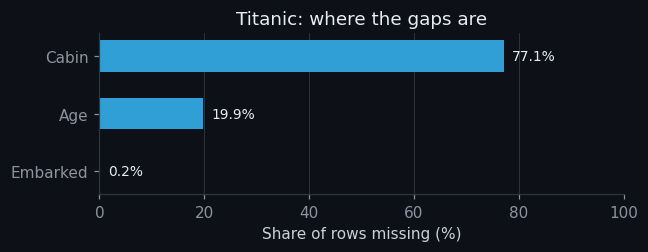

In [4]:
missing = df.isna().mean().sort_values()
missing = missing[missing > 0]

plt.figure(figsize=(6, 2.4))
plt.barh(range(len(missing)), missing.values * 100, color=CYAN, height=0.55)
plt.yticks(range(len(missing)), missing.index)
for i, share in enumerate(missing.values):
    plt.text(share * 100 + 1.5, i, f"{share:.1%}", va="center", color=INK, fontsize=9)
plt.xlim(0, 100)
plt.xlabel("Share of rows missing (%)")
plt.title("Titanic: where the gaps are")
plt.grid(axis="y", visible=False)
plt.tight_layout()
save_plot("titanic_missingness.png")
summary["titanic_missing_share"] = missing.round(4).to_dict()

**Observations.** 891 passengers and 12 columns. 38.4% survived, so always guessing
"did not survive" already scores 61.6% accuracy, and any model has to beat that.
`Cabin` is missing for 77% of passengers, `Age` for 20%, and `Embarked` for 2 people.
`PassengerId` is an identifier, `Survived` is the label, and the other columns are
candidate features.

## Part B: Feature engineering

Four new features, each built from information known before the voyage: family size,
travelling alone, the title from the name, and the log of the fare. Each one uses only the
passenger's own row and learns nothing from other passengers, so it is safe to compute
before the split. None of them may use `Survived`.

In [5]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip()
df["Title"] = df["Title"].where(df["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Other")
df["LogFare"] = np.log1p(df["Fare"])

display(df[["Name", "Title", "FamilySize", "IsAlone", "Fare", "LogFare"]].head())
display(df["Title"].value_counts().to_frame("passengers"))

,Name,Title,FamilySize,IsAlone,Fare,LogFare
0,"Braund, Mr. Owen Harris",Mr,2,0,7.2500,2.110213
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,2,0,71.2833,4.280593
2,"Heikkinen, Miss. Laina",Miss,1,1,7.9250,2.188856
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,2,0,53.1000,3.990834
4,"Allen, Mr. William Henry",Mr,1,1,8.0500,2.202765


,passengers
Title,
Mr,517
Miss,182
Mrs,125
Master,40
Other,27


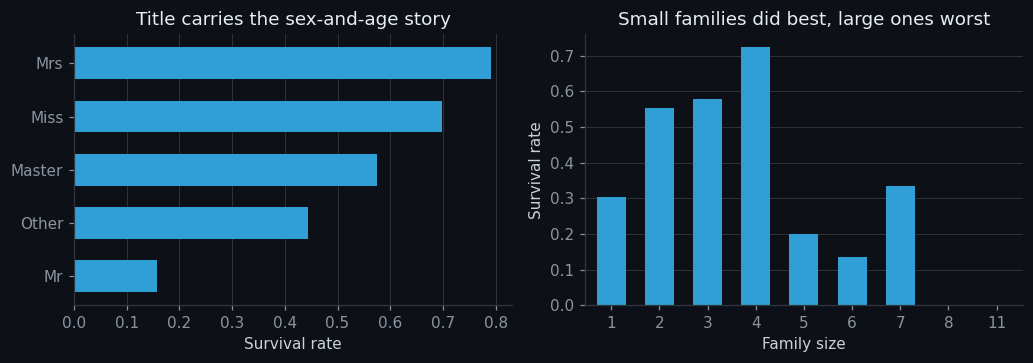

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
df.groupby("Title")["Survived"].mean().sort_values().plot.barh(ax=axes[0], color=CYAN, width=0.6)
axes[0].set_xlabel("Survival rate")
axes[0].set_ylabel("")
axes[0].set_title("Title carries the sex-and-age story")
axes[0].grid(axis="y", visible=False)
df.groupby("FamilySize")["Survived"].mean().plot.bar(ax=axes[1], rot=0, color=CYAN, width=0.6)
axes[1].set_xlabel("Family size")
axes[1].set_ylabel("Survival rate")
axes[1].set_title("Small families did best, large ones worst")
axes[1].grid(axis="x", visible=False)
plt.tight_layout()
save_plot("titanic_engineered_features.png")

**Observations.** Title separates survival well: 79% of passengers titled Mrs and 70% of
those titled Miss survived, against 16% of men titled Mr. Boys (Master) sit at 58%, an age
effect that `Sex` alone cannot show. Passengers travelling alone survived 30% of the time and
families of 2 to 4 between 55% and 72%. Families of 5 and 6 did worse than people travelling
alone (20% and 14%), and none of the 13 people in families of 8 or 11 survived.

Now compare the original columns with the engineered ones, using the same model and the
same split. Imputation, scaling and encoding sit inside the pipeline, so they learn only from
training rows.

In [7]:
y = df["Survived"]
feature_sets = {
    "raw columns": (["Age", "SibSp", "Parch", "Fare"], ["Pclass", "Sex", "Embarked"]),
    "raw + engineered": (["Age", "SibSp", "Parch", "LogFare", "FamilySize", "IsAlone"],
                         ["Pclass", "Sex", "Embarked", "Title"]),
}


def validation_auc(num_cols, cat_cols):
    X = df[num_cols + cat_cols]
    X_train, X_valid, y_train, y_valid = train_test_split(
        X, y, test_size=0.25, random_state=42, stratify=y
    )
    model = Pipeline([
        ("preprocess", make_preprocess(num_cols, cat_cols)),
        ("model", LogisticRegression(max_iter=2000)),
    ]).fit(X_train, y_train)
    return roc_auc_score(y_valid, model.predict_proba(X_valid)[:, 1])


feature_auc = {}
for name, (num_cols, cat_cols) in feature_sets.items():
    feature_auc[name] = validation_auc(num_cols, cat_cols)
    print(f"{name:18s} validation ROC AUC = {feature_auc[name]:.3f}")

raw columns        validation ROC AUC = 0.842
raw + engineered   validation ROC AUC = 0.872


**Observations.** Validation ROC AUC rises from 0.842 with the raw columns to 0.872 with the
engineered ones. The model, the split and the seed are identical, so the 0.03 gain comes from
the features.

### Try it yourself: cabin initial and fare per family member

The cabin initial is the deck letter, with `U` when the cabin is unknown. Fare per family
member divides the fare by family size. Each one goes on top of the engineered set, then both
together.

engineered + cabin       validation ROC AUC = 0.868
engineered + fare/family validation ROC AUC = 0.872
engineered + both        validation ROC AUC = 0.868


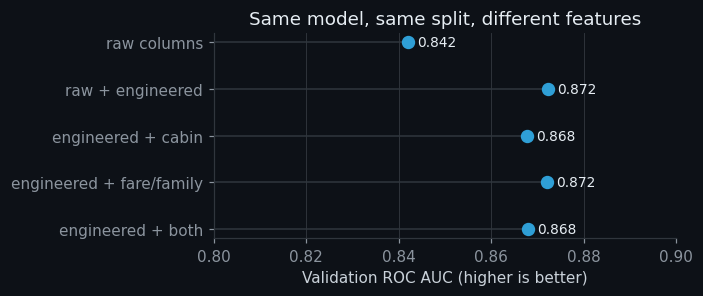

In [8]:
df["CabinInitial"] = df["Cabin"].str[0].fillna("U")
df["FarePerFamily"] = df["Fare"] / df["FamilySize"]

num_cols, cat_cols = feature_sets["raw + engineered"]
extensions = {
    "engineered + cabin": (num_cols, cat_cols + ["CabinInitial"]),
    "engineered + fare/family": (num_cols + ["FarePerFamily"], cat_cols),
    "engineered + both": (num_cols + ["FarePerFamily"], cat_cols + ["CabinInitial"]),
}
for name, (n, c) in extensions.items():
    feature_auc[name] = validation_auc(n, c)
    print(f"{name:24s} validation ROC AUC = {feature_auc[name]:.3f}")

auc_table = pd.Series(feature_auc, name="validation_roc_auc")
auc_table.to_csv(RESULTS / "feature_comparison.csv", index_label="features")
summary["feature_auc"] = auc_table.round(4).to_dict()

# A dot plot: the values sit close together, and dots do not need a zero baseline.
ordered = auc_table.iloc[::-1]
rows = range(len(ordered))
plt.figure(figsize=(6.5, 2.8))
plt.hlines(rows, 0.80, ordered.values, color=GRID, linewidth=1)
plt.scatter(ordered.values, rows, s=60, color=CYAN, zorder=3)
for i, value in enumerate(ordered.values):
    plt.text(value + 0.002, i, f"{value:.3f}", va="center", color=INK, fontsize=9)
plt.yticks(rows, ordered.index)
plt.xlim(0.80, 0.90)
plt.xlabel("Validation ROC AUC (higher is better)")
plt.title("Same model, same split, different features")
plt.grid(axis="y", visible=False)
plt.tight_layout()
save_plot("titanic_feature_comparison.png")

**Observations.** Neither extra feature helps on this split. Fare per family member scores
0.872, level with the engineered set, while the cabin initial and both together drop to 0.868.
`Cabin` is missing for 77% of passengers, so the letter is mostly `U`, and ticket class and
fare already carry most of what the deck says about a passenger.

## Part C: Scaling changes the geometry

The breast cancer measurements use very different units: `area_mean` runs into the thousands
while `smoothness_mean` stays below 1. Compare Euclidean distances between the first five
tumours before and after standardizing. This is a geometry demo on all rows; inside a model
you would fit the scaler on training rows only.

In [9]:
cancer = pd.read_csv(DATA / "breast_cancer_dataset.csv")
feature_cols = [c for c in cancer.columns if c not in {"id", "diagnosis", "Unnamed: 32"}]
X_cancer = cancer[feature_cols]

three = ["area_mean", "texture_mean", "smoothness_mean"]
display(X_cancer[three].describe().loc[["mean", "std"]].round(3))

,area_mean,texture_mean,smoothness_mean
mean,654.889,19.290,0.096
std,351.914,4.301,0.014


Darker cells mean closer pairs. Tumours are numbered 1 to 5.

closest pair in raw units:    (3, 5)
closest pair after scaling:   (2, 5)


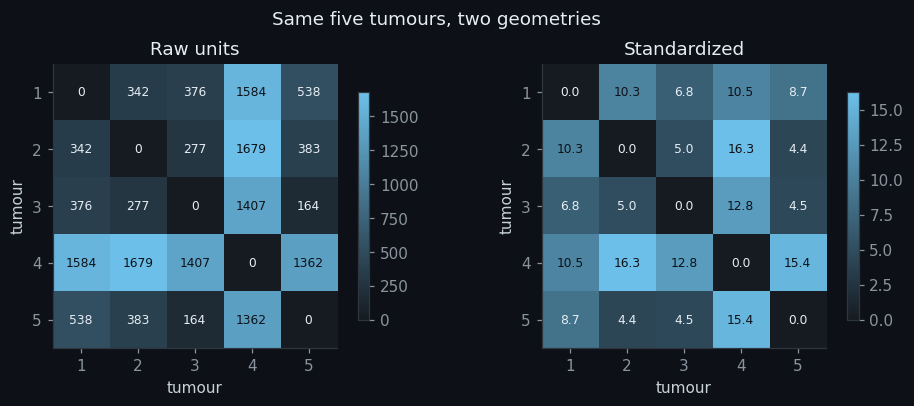

In [10]:
raw = pairwise_distances(X_cancer.iloc[:5], metric="euclidean")
X_scaled = StandardScaler().fit_transform(X_cancer)
scaled = pairwise_distances(X_scaled[:5], metric="euclidean")


def closest_pair(matrix):
    i, j = np.triu_indices_from(matrix, k=1)
    k = matrix[i, j].argmin()
    return int(i[k]) + 1, int(j[k]) + 1


print("closest pair in raw units:   ", closest_pair(raw))
print("closest pair after scaling:  ", closest_pair(scaled))
summary["closest_pair"] = {"raw": closest_pair(raw), "standardized": closest_pair(scaled)}

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, matrix, title, fmt in [(axes[0], raw, "Raw units", ".0f"),
                               (axes[1], scaled, "Standardized", ".1f")]:
    im = ax.imshow(matrix, cmap=HEAT)
    ax.set_title(title)
    ax.set_xlabel("tumour")
    ax.set_ylabel("tumour")
    ax.set_xticks(range(5), labels=range(1, 6))
    ax.set_yticks(range(5), labels=range(1, 6))
    ax.grid(False)
    for i in range(5):
        for j in range(5):
            color = "#0d1117" if matrix[i, j] > matrix.max() * 0.55 else INK
            ax.text(j, i, format(matrix[i, j], fmt), ha="center", va="center", color=color, fontsize=8)
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.suptitle("Same five tumours, two geometries")
plt.tight_layout()
save_plot("scaling_geometry.png")

**Observations.** `area_mean` has a standard deviation of 352 and `smoothness_mean` one of
0.014, so the raw distances are almost pure area differences. In raw units tumours 3 and 5
are the closest pair; after standardizing, tumours 2 and 5 are. A method built on distances,
like k-nearest neighbours or k-means, would pick different neighbours depending on the units.

## Part D: Feature selection without leakage

Predict the final grade `G3` for 649 students at enrolment. `G1` and `G2` are grades from
later in the year, so they are out, which leaves 30 candidate columns. Every selection step
sits inside a pipeline, so it only ever sees training rows.

In [11]:
students = pd.read_csv(DATA / "student_performance_dataset.csv")
print("shape:", students.shape, " missing:", students.isna().sum().sum(),
      " duplicates:", students.duplicated().sum())

target = "G3"
leaky = ["G1", "G2"]
X_s = students.drop(columns=[target] + leaky)
y_s = students[target]
s_num = X_s.select_dtypes(include="number").columns.tolist()
s_cat = X_s.select_dtypes(exclude="number").columns.tolist()
print(len(s_num), "numeric and", len(s_cat), "text features available at enrolment")

Xs_train, Xs_valid, ys_train, ys_valid = train_test_split(X_s, y_s, test_size=0.25, random_state=42)

shape: (649, 33)  missing: 0  duplicates: 0
13 numeric and 17 text features available at enrolment


Ridge with all 30 features, ridge with the best `k` features from SelectKBest (k=10 from the
handout, k=5 and k=20 from *Try it yourself*), and lasso, which selects by itself. The last
run adds `G2` on purpose to show what leakage looks like.

In [12]:
def evaluate(pipeline, X_tr, X_va, label):
    pipeline.fit(X_tr, ys_train)
    mae = mean_absolute_error(ys_valid, pipeline.predict(X_va))
    print(f"{label:24s} validation MAE = {mae:.3f} grade points")
    return mae


results = {}
results["all 30 features"] = evaluate(Pipeline([
    ("preprocess", make_preprocess(s_num, s_cat)),
    ("model", Ridge(alpha=1.0)),
]), Xs_train, Xs_valid, "all 30 features")

selectors = {}
for k in [5, 10, 20]:
    selectors[k] = Pipeline([
        ("preprocess", make_preprocess(s_num, s_cat)),
        ("select", SelectKBest(f_regression, k=k)),
        ("model", Ridge(alpha=1.0)),
    ])
    results[f"SelectKBest, k={k}"] = evaluate(selectors[k], Xs_train, Xs_valid, f"SelectKBest, k={k}")

lasso = Pipeline([
    ("preprocess", make_preprocess(s_num, s_cat)),
    ("model", Lasso(alpha=0.1)),
])
results["lasso (selects itself)"] = evaluate(lasso, Xs_train, Xs_valid, "lasso (selects itself)")

leak_num = s_num + ["G2"]
results["all 30 + G2 (leakage)"] = evaluate(Pipeline([
    ("preprocess", make_preprocess(leak_num, s_cat)),
    ("model", Ridge(alpha=1.0)),
]), Xs_train.assign(G2=students.loc[Xs_train.index, "G2"]),
    Xs_valid.assign(G2=students.loc[Xs_valid.index, "G2"]), "all 30 + G2 (leakage)")

mae_table = pd.Series(results, name="validation_mae")
mae_table.to_csv(RESULTS / "student_feature_selection.csv", index_label="model")
summary["student_mae"] = mae_table.round(4).to_dict()

all 30 features          validation MAE = 2.181 grade points
SelectKBest, k=5         validation MAE = 2.134 grade points
SelectKBest, k=10        validation MAE = 2.139 grade points
SelectKBest, k=20        validation MAE = 2.125 grade points
lasso (selects itself)   validation MAE = 2.077 grade points


all 30 + G2 (leakage)    validation MAE = 0.762 grade points


lasso kept 18 of 56 encoded columns
of those, effectively zero (|coef| < 1e-9): ['cat__school_MS', 'cat__higher_yes']
SelectKBest, k=10 kept: ['num__Medu', 'num__studytime', 'num__failures', 'num__Dalc', 'cat__school_GP', 'cat__school_MS', 'cat__reason_other', 'cat__reason_reputation', 'cat__higher_no', 'cat__higher_yes']


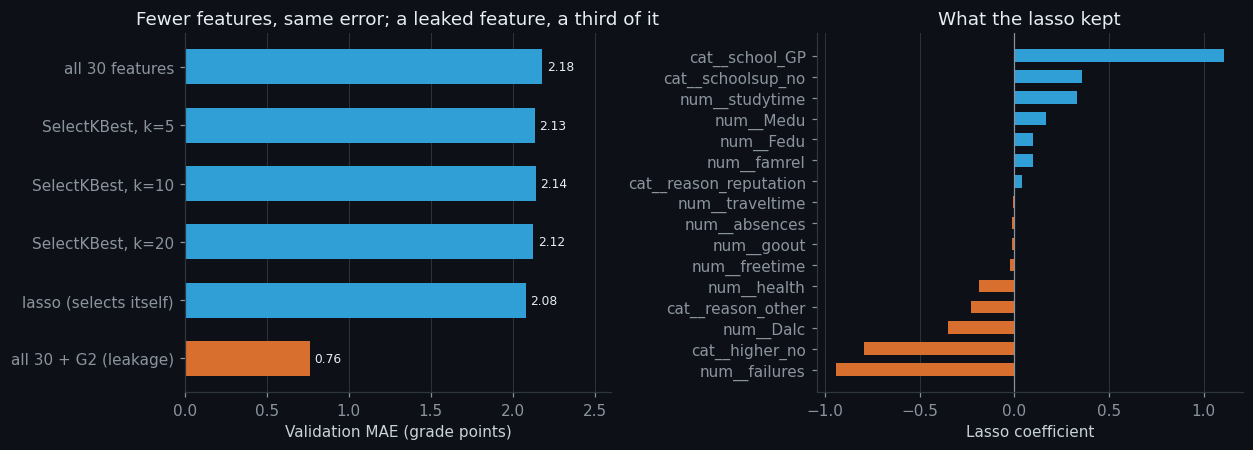

In [13]:
coefs = pd.Series(lasso.named_steps["model"].coef_,
                  index=lasso.named_steps["preprocess"].get_feature_names_out())
kept = coefs[coefs != 0].sort_values()
print(f"lasso kept {len(kept)} of {len(coefs)} encoded columns")
print("of those, effectively zero (|coef| < 1e-9):", kept[kept.abs() < 1e-9].index.tolist())
names = selectors[10].named_steps["preprocess"].get_feature_names_out()
print("SelectKBest, k=10 kept:", names[selectors[10].named_steps["select"].get_support()].tolist())
summary["lasso_kept"] = {"nonzero": int(len(kept)), "above_1e-9": int((kept.abs() >= 1e-9).sum()),
                         "encoded_columns": int(len(coefs))}

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
labels = list(results)[::-1]
values = [results[label] for label in labels]
bars = axes[0].barh(labels, values, height=0.6,
                    color=[ORANGE if "leakage" in label else CYAN for label in labels])
axes[0].bar_label(bars, fmt="%.2f", padding=3, color=INK, fontsize=8)
axes[0].set_xlim(0, 2.6)
axes[0].set_xlabel("Validation MAE (grade points)")
axes[0].set_title("Fewer features, same error; a leaked feature, a third of it")
axes[0].grid(axis="y", visible=False)
real = kept[kept.abs() >= 1e-9]
axes[1].barh(real.index, real.values, height=0.6, color=np.where(real.values >= 0, CYAN, ORANGE))
axes[1].axvline(0, color=MUTED, linewidth=0.8)
axes[1].set_xlabel("Lasso coefficient")
axes[1].set_title("What the lasso kept")
axes[1].grid(axis="y", visible=False)
plt.tight_layout()
save_plot("student_selection.png")

(RESULTS / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8");

**Observations.**

- All 30 features give a validation MAE of 2.18 grade points. SelectKBest with 10 columns gets
  2.14, and the *Try it yourself* runs land close by: 2.13 with k=5 and 2.12 with k=20. On
  this split, a third of the columns loses nothing.
- Lasso does best at 2.08. The handout's `coef_ != 0` test counts 18 kept columns out of 56,
  but two of them (`school_MS` and `higher_yes`) are around 1e-15. That is floating-point
  noise from one-hot pairs that always sum to 1, so lasso keeps 16 columns in practice.
- Past failures and not planning on higher education pull the predicted grade down the most;
  attending the GP school and studying more push it up. These are associations in this
  sample, not causes.
- Adding `G2` cuts the error to 0.76. That model is useless for an enrolment forecast,
  because nobody knows `G2` at enrolment.

## Check your understanding

**1. Why must train/test splitting happen before any preprocessing step that learns from the data?**

Imputers, scalers, encoders and feature selectors all learn something from the rows they
see: a median, a mean and standard deviation, the list of categories, which columns score
best. If they see validation or test rows, information about those rows leaks into training
and the score comes out too optimistic. So split first, and fit every learned step on the
training rows only. A `Pipeline` enforces this, including inside each cross-validation fold.

**2. What is the difference between an identifier, a feature, and a label?**

An identifier only names a row (`PassengerId`, the tumour `id`). It carries nothing that
transfers to a new case, and a model can use it to memorise rows. A feature is an input you
know at prediction time, like age or ticket class. The label is the answer the model learns
to predict: `Survived` here, `G3` in Part D.

**3. Why do you need to know the moment of prediction before you can say whether a feature is leakage?**

Leakage depends on when the prediction happens. At enrolment `G2` lies in the future, so
using it is leakage. A forecast made after the second grading period could use `G2`
legitimately. The same question applies to `absences`, which build up during the school
year: the handout keeps them, but a strict enrolment-day model would not have them yet.